## Sample Exploration

This script contains exploration of basic associations in our data across adversity, mental health, and polygenic scores (PGS).

Example data is provided in order to run the code. All original data is avaliable on the NBDC Data Hub (https://www.nbdc-datahub.org/).

Written by: Alexa Mousley (alexa.mousley@mrc-cbu.cam.ac.uk)
*October 2026*

In [1]:
### Import packages ###

from A_config import  *                         # Import custom paths
from A_functions import *                       # Custom functions/colors
import os                                       # For combining paths
import numpy as np                              # Basic requirements 
import pandas as pd                             # Basic requirements
import matplotlib.pyplot as plt                 # Plotting
import seaborn as sns                           # Plotting
import pingouin as pg                           # Plotting
import plotly.express as px                     # Plotting
import scipy.stats as stats                     # Statistics (e.g., zscore, pearsonr)


In [ ]:
### Load data ###

# Associated data
associated_data = pd.read_csv(os.path.join(data_dir,"associated_data_example.csv"))

# Subsample associated data
subsample_associated_data = pd.read_csv(os.path.join(data_dir,"subsample_associated_data_example.csv"))

# Adversity data
adversity_labels = ['Household_Community_Instability','Physical_Sexual_Abuse','Parental_Neglect','Financial_Difficulties']
adversity = associated_data[adversity_labels].values

# Polygenic scores
pgs_labels = subsample_associated_data.loc[:, 'CT':'VasDem'].columns.tolist()
pgs = subsample_associated_data[pgs_labels]

# Set up PGS labeling
definitions = {
    # Brain morphology
    'CT': 'Cortical thickness','SA' : 'Surface area', 'Volume' : 'Brain volume', 'ICI' : 'Intrinsic curvature index','GC' : 'Gaussian curvature','FI' : 'Folding index','MC' : 'Mean curvature',
    # White matter microstructure
    'FA' : 'Fractional anisotropy','MD'  : 'Mean diffusivity','ISOVF' : 'Isotropic volume fraction','ICVF' : 'Intracellular volume fraction','OD' : 'Orientation dispersion index',
    # Neurodevelopmental
    'ADHD' : 'ADHD diagnosis','Adult ADHD' : 'ADHD diagnosis (adult onset)','Child ADHD' : 'ADHD diagnosis (childhood onset)','ASD' : 'Autism spectrum disorder','Early ASD' : 'Early ASD diagnosis','Late ASD' : 'Late ASD diagnosis',
    # Psychiatric
    'Anxiety' : 'Anxiety disorder','BIP' : 'Bipolar disorder','BIP Type 1' : 'Type 1 Bipolar disorder','BIP Type 2' : 'Type 2 Bipolar disorder','MDD' : 'Major depressive disorder','Panic' : 'Panic disorder',
    'Anorexia' : 'Anorexia nervosa','OCD'  : 'Obsessive compulsive disorder','PTSD' : 'Post-traumatic stress disorder','SCZ' : 'Schizophrenia','SUD' : 'Substance use disorder',
    # Neurological & neurodegenerative
    'ALS' : 'Amyotrophic lateral sclerosis','ALZ' : 'Alzheimer\'s disease','Glioma' : 'Glioma','PD' : 'Parkinson\'s disease','VasDem' : 'Vascular dementia',
}

categories = {
    'Brain morphology'                 : ['CT', 'SA', 'Volume', 'ICI', 'GC', 'FI', 'MC'],
    'White matter microstructure'      : ['FA', 'MD', 'ISOVF', 'ICVF', 'OD'],
    'Neurodevelopmental diagnosis'               : ['ADHD', 'Adult ADHD', 'Child ADHD',
                                          'ASD', 'Early ASD', 'Late ASD'],
    'Psychiatric conditions'                      : ['Anxiety', 'BIP', 'BIP Type 1', 'BIP Type 2',
                                          'MDD', 'Panic', 'Anorexia', 'OCD', 'PTSD',
                                          'SCZ', 'SUD'],
    'Neurological & neurodegenerative conditions' : ['ALS', 'ALZ', 'Glioma', 'PD', 'VasDem'],
}

### Print basic statistics ###
columns = ['age', 'sex', 'mental_health_score', 'total_adversity']
descriptive_stats(associated_data, columns)


DESCRIPTIVE STATISTICS

Total N: 7384

Variable                  Min      Max     Mean   Median       SD
--------------------------------------------------------------------------------
age                    107.00   133.00   119.01   119.00     7.52
mental_health_score     24.00    81.00    45.44    45.00    11.15
total_adversity          0.00    17.80     4.30     3.80     2.04

Male       n = 3830  (51.9%)
Female     n = 3554  (48.1%)


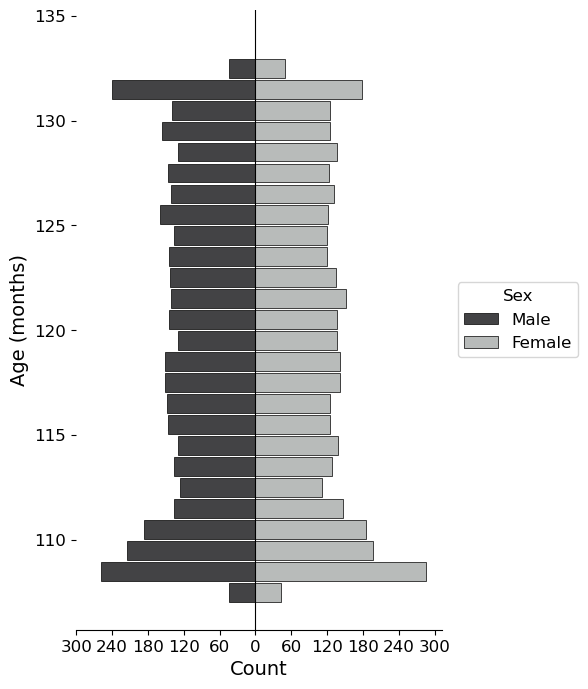

In [10]:
### FIGURE 1a ###

plot_demo_pyramid(
    associated_data,
    age_col='age',
    sex_col='sex',
    save_dir=save_dir,
    name='age_sex_pyramid',
    sex_labels={1.0: 'Male', 2.0: 'Female'},   
    colors={'Male': "#434345", 'Female': "#B8BBBA"},   
    age_label='Age (months)',
)

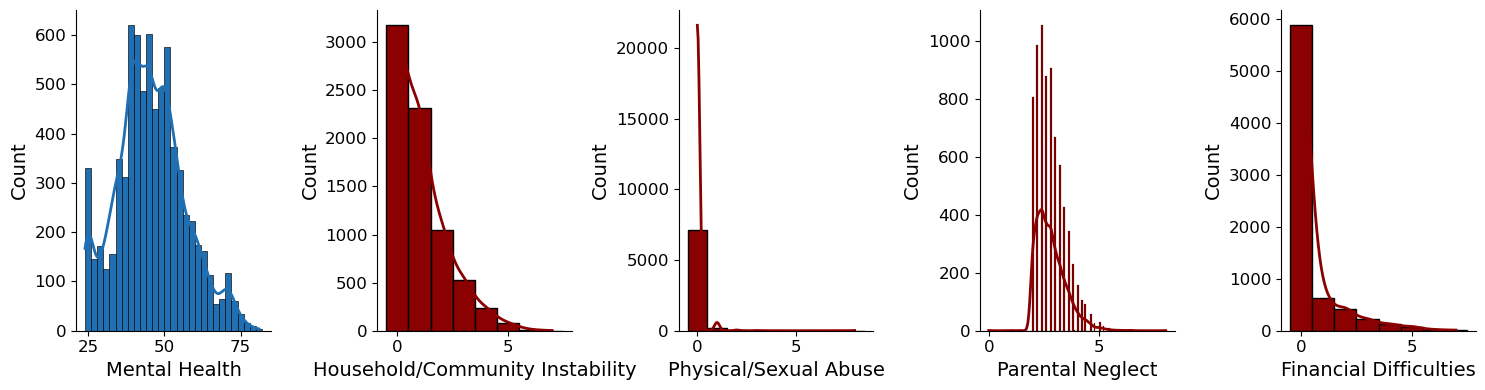

In [11]:
### FIGURE 1b ###

# Create label-column asssociations
labels = ['Mental Health','Household/Community Instability','Physical/Sexual Abuse','Parental Neglect','Financial Difficulties']
columns = ['mental_health_score','Household_Community_Instability', 'Physical_Sexual_Abuse', 'Parental_Neglect', 'Financial_Difficulties']

# Create dataframe
data = pd.DataFrame({
    columns[0]: associated_data[columns[0]].values,
    columns[1]: associated_data[columns[1]].values,
    columns[2]: associated_data[columns[2]].values,
    columns[3]: associated_data[columns[3]].values,
    columns[4]: associated_data[columns[4]].values
})

# Plot
plot_histograms(data, columns, labels, save_dir)

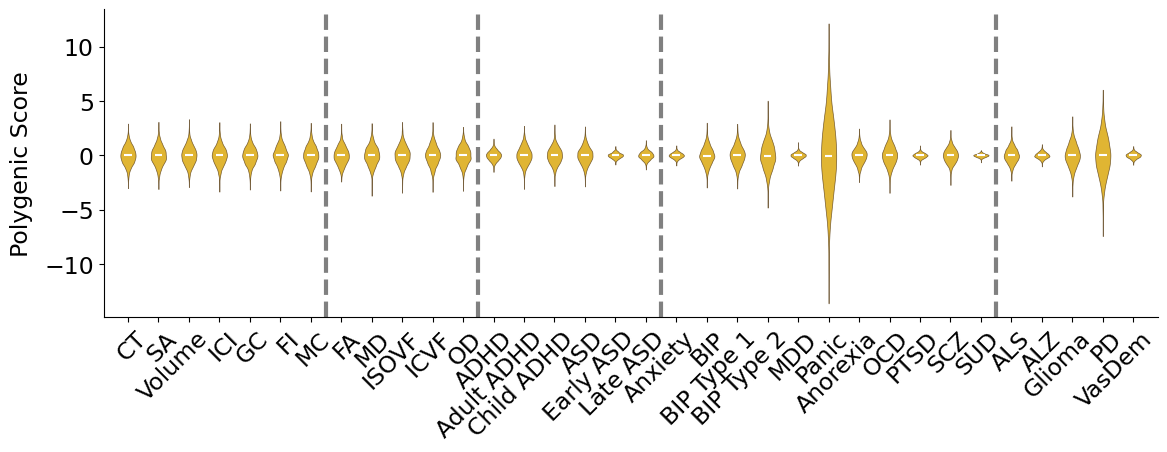

In [12]:
### FIGURE 1b ###

plot_pgs_violins(pgs, pgs_labels, categories, save_path=save_dir)

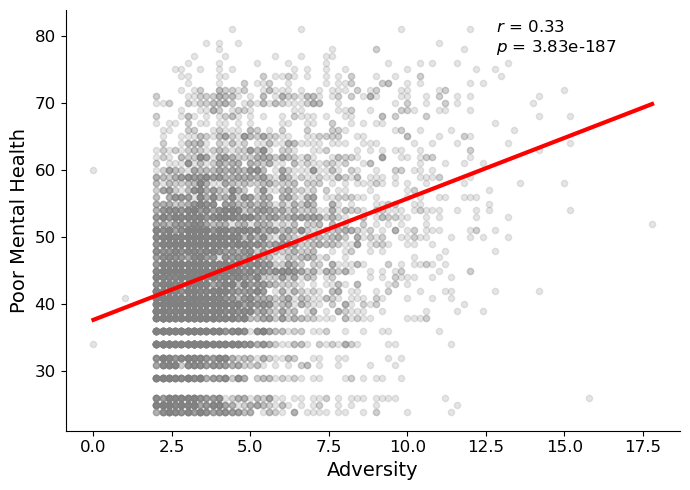

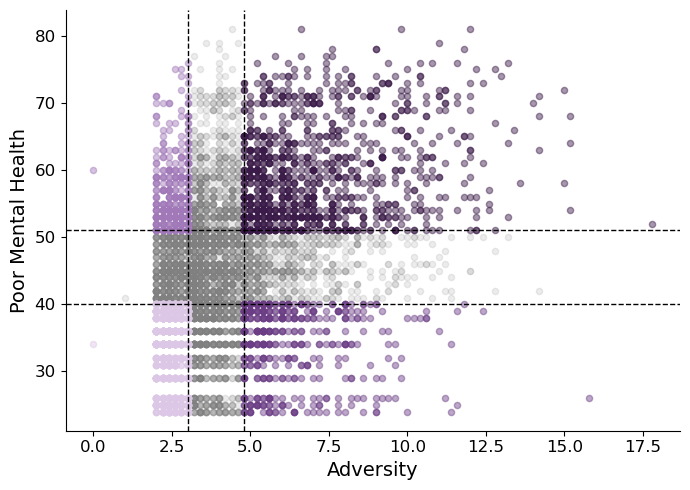

{'High / High': (1078, 14.6),
 'High / Low': (474, 6.4),
 'Low / High': (407, 5.5),
 'Low / Low': (1079, 14.6),
 'Middle (grey)': (4346, 58.9)}

In [18]:
### Examine adversity-mental health relationship ###

# Create variable labels
labels = ['Poor Mental Health','Adversity']
columns = ['mental_health_score','total_adversity']

# Create dataframe
data = pd.DataFrame({
    columns[0]: associated_data[columns[0]].values,
    columns[1]: associated_data[columns[1]].values
})

# Standardize
z_data = data.copy()
for col in columns:
    z_data[col] = stats.zscore(z_data[col])

# Define pair to compare 
y_label, x_label = 'Poor Mental Health','Adversity'

### FIGURE 1c ###
plot_corr(data, columns, labels, x_label, y_label, save_dir)

### FIGURE 1e ###
plot_quadrants(data, columns, labels, x_label, y_label, save_dir)

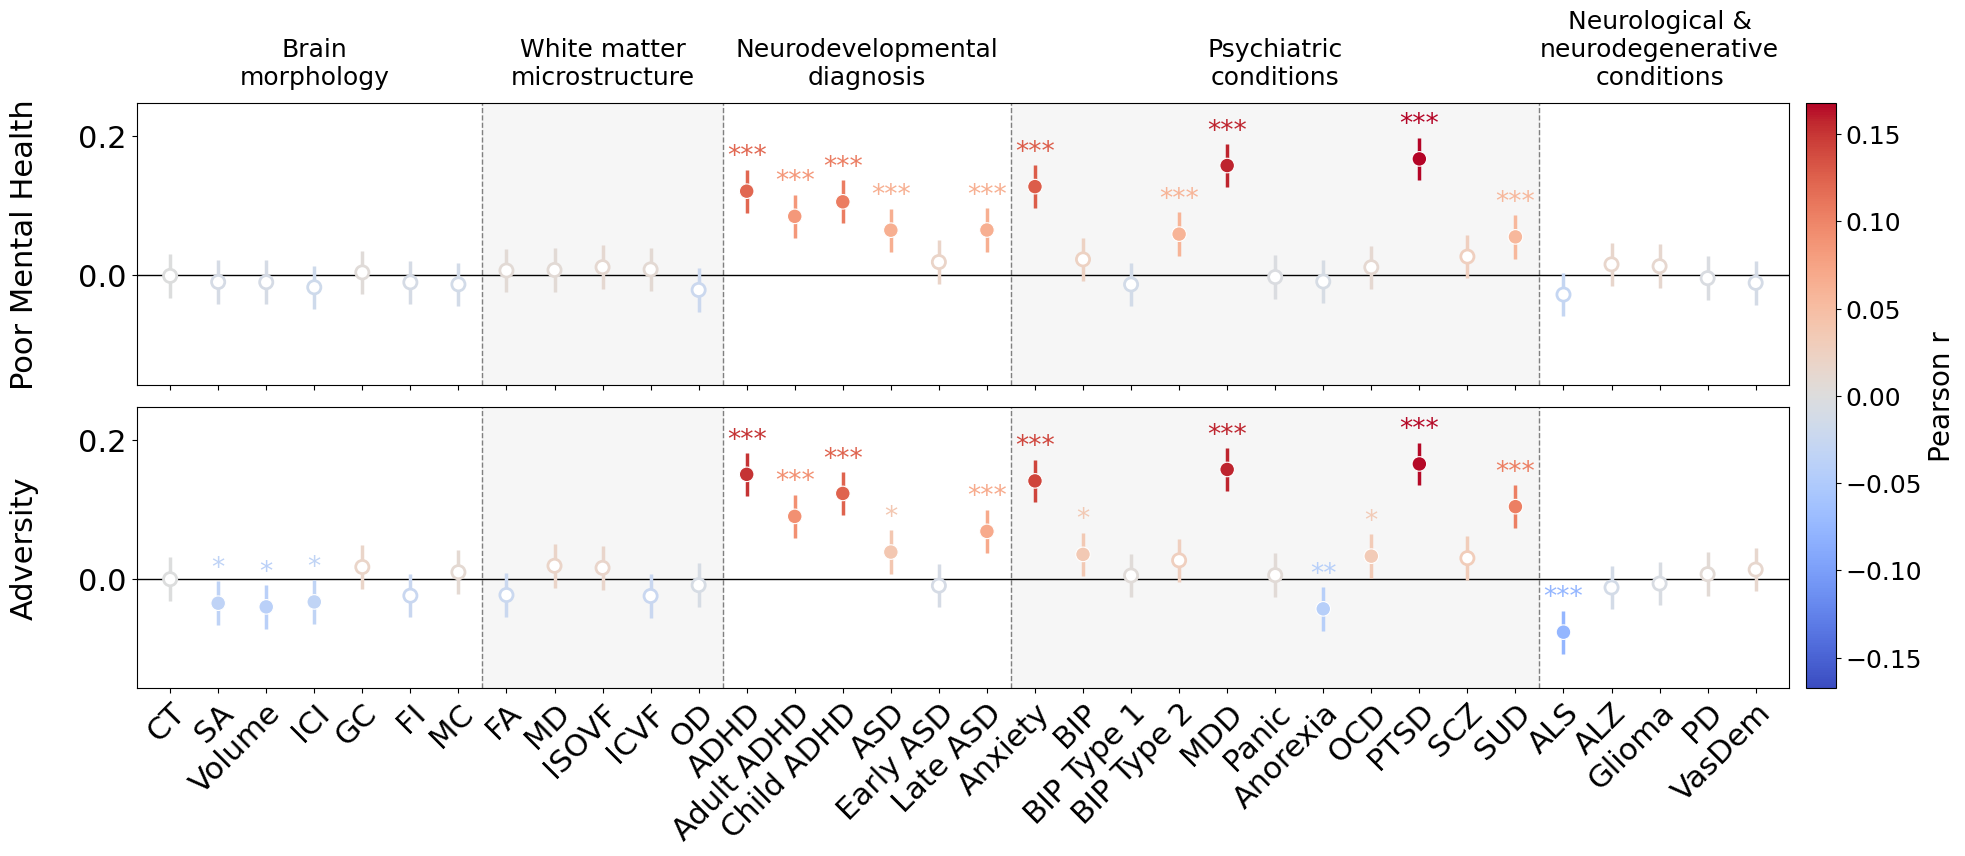

In [19]:
### FIGURE 1d ###

# Pull data from genetic subsample
data = subsample_associated_data[columns].copy()
data.columns = columns 

# Plot
plot_pgs_corrs(pgs, pgs_labels, data, labels, categories, save_path=save_dir)